In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')

In [15]:
# Load dataset (assuming file is in same directory)
df = pd.read_csv('/content/Churn_Modelling.csv')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [16]:
# Check info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [17]:
# Check for missing values
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


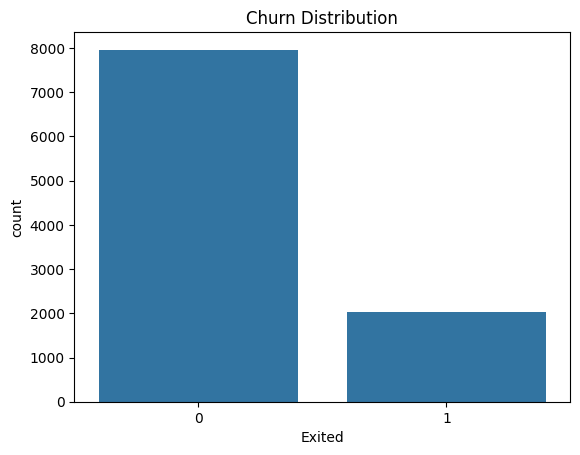

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


In [18]:
# Target distribution
sns.countplot(x='Exited', data=df)
plt.title('Churn Distribution')
plt.show()
print(df['Exited'].value_counts(normalize=True))

In [19]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)
print("New shape:", df.shape)

New shape: (10000, 11)


In [20]:
# One-hot encode Geography
df = pd.get_dummies(df, columns=['Geography'], drop_first=True)  # drop first to avoid multicollinearity

# Label encode Gender
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])  # Female=0, Male=1

df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


In [21]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (8000, 11)
Test set shape: (2000, 11)


In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test_scaled)

# Confusion Matrix and Accuracy
cm_svm = confusion_matrix(y_test, y_pred_svm)
acc_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Confusion Matrix:")
print(cm_svm)
print("\nSVM Accuracy: {:.4f}".format(acc_svm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Confusion Matrix:
[[1561   32]
 [ 246  161]]

SVM Accuracy: 0.8610

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.92      1593
           1       0.83      0.40      0.54       407

    accuracy                           0.86      2000
   macro avg       0.85      0.69      0.73      2000
weighted avg       0.86      0.86      0.84      2000



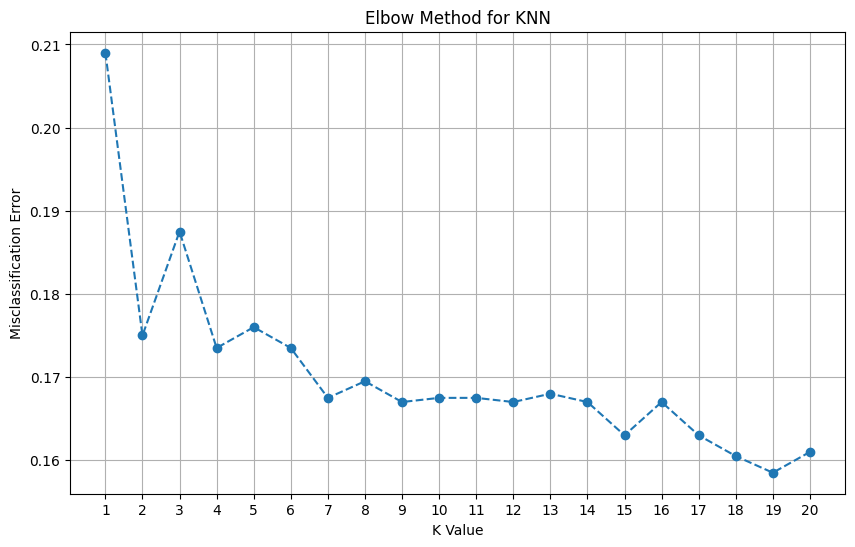

In [25]:
error_rate = []
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_k = knn.predict(X_test_scaled)
    error_rate.append(1 - accuracy_score(y_test, y_pred_k))

# Plot
plt.figure(figsize=(10,6))
plt.plot(range(1,21), error_rate, marker='o', linestyle='--')
plt.xlabel('K Value')
plt.ylabel('Misclassification Error')
plt.title('Elbow Method for KNN')
plt.xticks(range(1,21))
plt.grid(True)
plt.show()

In [26]:
# Choose optimal K (e.g., 5)
k_opt = 5
knn_opt = KNeighborsClassifier(n_neighbors=k_opt)
knn_opt.fit(X_train_scaled, y_train)
y_pred_knn = knn_opt.predict(X_test_scaled)

cm_knn = confusion_matrix(y_test, y_pred_knn)
acc_knn = accuracy_score(y_test, y_pred_knn)

print("KNN (K={}) Confusion Matrix:".format(k_opt))
print(cm_knn)
print("\nKNN Accuracy: {:.4f}".format(acc_knn))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN (K=5) Confusion Matrix:
[[1508   85]
 [ 267  140]]

KNN Accuracy: 0.8240

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.95      0.90      1593
           1       0.62      0.34      0.44       407

    accuracy                           0.82      2000
   macro avg       0.74      0.65      0.67      2000
weighted avg       0.80      0.82      0.80      2000

